<a href="https://colab.research.google.com/github/Wallace139/Hello-world/blob/master/AI4_Lab1b_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1b, and your CW1 notebook (classification)

**ENG4200 / ENG5338**

For **Stroke, Telco and Steel Plates**. (Abalone, Air Quality and Gas Turbine: use the regression notebook.)

**This notebook is your CW1 notebook.** CW1 is two files:

1. your report: a PDF of at most 5 pages on the template, named `ENG4200_CW1_<your ID>.pdf`;
2. this notebook, filled in and run from top to bottom, named `ENG4200_CW1_<your ID>.ipynb`.

ENG5338 students name both `ENG5338_CW1_<your ID>`.

**Part 1** is Lab 1a: copy your answers across. **Part 2** applies Tutorial 2 to your data.
Each `___` is yours to fill in. The blanks are the minimum: add cells wherever your report needs more.

CPU runtime in Colab.

In [2]:
#@title Run this first: course helper module (ai4_tools). Double-click to see the code.
# ENG4200 / ENG5338 helper module. Source of truth is notebooks/ai4_tools.py in the
# course repository. Do not edit here: edit there and rerun build_toolcell.py, or the
# change is lost the next time the notebook is reissued.
_AI4_TOOLS_SOURCE = r'''
"""
ai4_tools: runtime reporting and cost measurement for ENG4200 / ENG5338.

Why this exists. The courseworks ask for computational efficiency: training time,
inference latency and memory footprint. A number timed on one runtime and compared
against a number timed on another is not evidence, so every timing this module produces
carries the runtime it was measured on.

Use it like this:

    show_runtime()                       # once, at the top of every notebook
    r = benchmark(model, Xtr, ytr, Xte, yte)
    table = ResultsTable(); table.add("logistic regression", r); table.df()
    decision("Stratified 5-fold", "3.4% positives, plain k-fold can empty a fold", r)

Standard library plus numpy only. pandas, scikit-learn, torch and psutil are all optional
and are used if present. Written for Python 3.8 and later so it runs on Colab, on the lab
machines and on a student laptop without changes.
"""

import gc
import importlib.util
import os
import platform
import statistics
import subprocess
import sys
import threading
import time
import tracemalloc
from contextlib import contextmanager

__all__ = [
    "runtime_info", "runtime_line", "show_runtime",
    "timed", "benchmark", "peak_memory",
    "ResultsTable", "decision",
    "register_sections", "check", "check_raises", "scorecard", "reset_checks",
]

_MB = 1024.0 * 1024.0


# ----------------------------------------------------------------------------------
# Runtime description
# ----------------------------------------------------------------------------------

def _have(name):
    """True if a module is importable, without importing it."""
    try:
        return importlib.util.find_spec(name) is not None
    except (ImportError, ValueError):
        return False


def _cpu_model():
    system = platform.system()
    try:
        if system == "Linux":
            with open("/proc/cpuinfo") as fh:
                for line in fh:
                    if line.startswith("model name"):
                        return line.split(":", 1)[1].strip()
        elif system == "Darwin":
            out = subprocess.check_output(
                ["sysctl", "-n", "machdep.cpu.brand_string"],
                stderr=subprocess.DEVNULL, timeout=5,
            )
            return out.decode().strip()
    except Exception:
        pass
    return platform.processor() or platform.machine() or "unknown CPU"


def _total_ram_gb():
    try:
        import psutil  # noqa: F401
        return psutil.virtual_memory().total / (1024 ** 3)
    except Exception:
        pass
    try:
        return (os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")) / (1024 ** 3)
    except (ValueError, OSError, AttributeError):
        return None


def _gpu_state():
    """(has_gpu, name). Reports what torch can actually use, not what is installed."""
    if "torch" not in sys.modules and not _have("torch"):
        return False, "torch not installed"
    try:
        import torch
        if torch.cuda.is_available():
            return True, torch.cuda.get_device_name(0)
        if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
            return True, "Apple MPS"
        return False, "none attached"
    except Exception as exc:
        return False, "torch present but unusable ({})".format(type(exc).__name__)


def runtime_info():
    """Everything that makes one timing comparable with another, as a dict."""
    has_gpu, gpu_name = _gpu_state()
    ram = _total_ram_gb()
    return {
        "platform": "Google Colab" if _have("google.colab") else platform.system(),
        "python": platform.python_version(),
        "cpu": _cpu_model(),
        "cores": os.cpu_count(),
        "ram_gb": round(ram, 1) if ram else None,
        "accelerator": gpu_name if has_gpu else "CPU only",
        "has_gpu": has_gpu,
    }


def runtime_line(info=None):
    """The one line that goes with every number you report. Paste it into the report."""
    i = info or runtime_info()
    ram = "{} GB".format(i["ram_gb"]) if i["ram_gb"] else "RAM unknown"
    return "{} | {} ({} cores, {}) | {} | Python {}".format(
        i["platform"], i["cpu"], i["cores"], ram, i["accelerator"], i["python"]
    )


def show_runtime():
    """Run this once at the top of every notebook. Returns the line so you can keep it."""
    info = runtime_info()
    line = runtime_line(info)
    print("Runtime:", line)
    if info["has_gpu"] and info["platform"] == "Google Colab":
        print(
            "\nA GPU is attached. scikit-learn cannot use it, so for Tutorials 1 to 4 it\n"
            "buys you nothing and spends a rationed allowance you will want in November\n"
            "for Lab 2 and CW3. Set Runtime > Change runtime type > CPU unless you are\n"
            "running PyTorch."
        )
    elif info["has_gpu"]:
        print("\nAn accelerator is available. scikit-learn will not use it; only PyTorch will.")
    return line


# ----------------------------------------------------------------------------------
# Timing
# ----------------------------------------------------------------------------------

@contextmanager
def timed(label="elapsed", quiet=False):
    """with timed('fit'): model.fit(X, y)   ->   seconds land in .seconds"""
    class _T:
        seconds = None
    t = _T()
    start = time.perf_counter()
    try:
        yield t
    finally:
        t.seconds = time.perf_counter() - start
        if not quiet:
            print("{}: {:.4f} s".format(label, t.seconds))


def _clone(model):
    try:
        from sklearn.base import clone
        return clone(model)
    except Exception:
        import copy
        return copy.deepcopy(model)


def _median_of(fn, repeats):
    """One warm-up run that is thrown away, then `repeats` timed runs. Median, not mean:
    a single slow run caused by something else on the machine should not move the number."""
    fn()
    samples = []
    for _ in range(repeats):
        gc.collect()
        start = time.perf_counter()
        fn()
        samples.append(time.perf_counter() - start)
    return statistics.median(samples), min(samples)


def benchmark(model, X_train, y_train, X_test, y_test=None, scorer=None,
              repeats=3, label=None, measure_memory=False):
    """Fit and predict cost for one model, on one runtime, in a form you can tabulate.

    Returns a dict with fit_s, predict_s, predict_ms_per_1k and the runtime line.
    `predict_ms_per_1k` is the one CW3 asks for, because inference latency has to be
    per unit of work or it just measures how big your test set happened to be.

    Note the difference from %timeit, which is fine for a demonstration but prints to the
    screen instead of returning a value you can put in a results table.
    """
    n_train = len(X_train)
    n_test = len(X_test)

    fit_median, fit_best = _median_of(lambda: _clone(model).fit(X_train, y_train), repeats)

    fitted = _clone(model).fit(X_train, y_train)
    pred_median, pred_best = _median_of(lambda: fitted.predict(X_test), repeats)

    score = None
    if y_test is not None:
        try:
            score = scorer(y_test, fitted.predict(X_test)) if scorer else fitted.score(X_test, y_test)
        except Exception as exc:
            print("Could not score this model: {}".format(exc))

    result = {
        "model": label or type(model).__name__,
        "score": score,
        "fit_s": fit_median,
        "fit_s_best": fit_best,
        "predict_s": pred_median,
        "predict_ms_per_1k": (pred_median / n_test) * 1000.0 * 1000.0 if n_test else None,
        "n_train": n_train,
        "n_test": n_test,
        "repeats": repeats,
        "runtime": runtime_line(),
    }

    if measure_memory:
        mb, metric = peak_memory(lambda: _clone(model).fit(X_train, y_train))
        result["peak_mem_mb"] = mb
        result["mem_metric"] = metric

    return result


# ----------------------------------------------------------------------------------
# Memory
# ----------------------------------------------------------------------------------

def _rss_bytes():
    """Current resident set size of this process, or None if we cannot read it.

    Resident set size, not the Python heap. scikit-learn's trees and torch's tensors are
    allocated in C, which tracemalloc never sees, so a tracemalloc figure for a random
    forest comes out roughly two orders of magnitude too small.
    """
    try:
        import psutil
        return psutil.Process().memory_info().rss
    except Exception:
        pass
    try:
        with open("/proc/self/statm") as fh:
            return int(fh.read().split()[1]) * os.sysconf("SC_PAGE_SIZE")
    except Exception:
        return None


def peak_memory(fn, interval=0.01):
    """Peak memory used by fn(), as (megabytes, which_metric).

    The second value is not decoration. Three different quantities can come back here
    depending on the runtime, and they are not interchangeable:

      GPU device memory      measured by torch when a CUDA device is attached
      host process RSS       peak resident memory minus the baseline, sampled while fn runs
      host Python heap       tracemalloc, the last resort, and an undercount for anything
                             that allocates in C, which includes scikit-learn and torch

    A table that does not say which one it holds cannot be compared with anyone else's.
    So the metric travels with the number.
    """
    has_gpu, _ = _gpu_state()
    if has_gpu:
        try:
            import torch
            if torch.cuda.is_available():
                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()
                fn()
                torch.cuda.synchronize()
                return torch.cuda.max_memory_allocated() / _MB, "GPU device memory (torch.cuda)"
        except Exception:
            pass

    gc.collect()
    baseline = _rss_bytes()
    if baseline is not None:
        peak = [baseline]
        stop = threading.Event()

        def _sample():
            while not stop.is_set():
                current = _rss_bytes()
                if current is not None and current > peak[0]:
                    peak[0] = current
                stop.wait(interval)

        watcher = threading.Thread(target=_sample, daemon=True)
        watcher.start()
        try:
            fn()
        finally:
            stop.set()
            watcher.join(timeout=1.0)
        return max(peak[0] - baseline, 0) / _MB, "host process RSS (peak minus baseline)"

    gc.collect()
    tracemalloc.start()
    try:
        fn()
        _, peak_traced = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return peak_traced / _MB, "host Python heap (tracemalloc, undercounts C allocations)"


# ----------------------------------------------------------------------------------
# Results table and decision log
# ----------------------------------------------------------------------------------

class ResultsTable:
    """Accumulates benchmark() rows. Every row keeps the runtime it was measured on, so
    a table assembled across two sessions cannot silently mix a CPU run with a GPU one."""

    def __init__(self):
        self.rows = []

    def add(self, label, result=None, **extra):
        if result is None:
            result = {}
        row = dict(result)
        row["model"] = label
        row.update(extra)
        self.rows.append(row)
        return self

    def df(self, columns=("model", "score", "fit_s", "predict_ms_per_1k")):
        try:
            import pandas as pd
        except ImportError:
            return self.rows
        frame = pd.DataFrame(self.rows)
        keep = [c for c in columns if c in frame.columns]
        rest = [c for c in frame.columns if c not in keep and c != "runtime"]
        return frame[keep + rest]

    def runtimes(self):
        """The distinct runtimes in this table. More than one means the timings in it
        are not comparable with each other, and the table needs splitting or rerunning."""
        return sorted({r.get("runtime") for r in self.rows if r.get("runtime")})

    def check(self):
        seen = self.runtimes()
        if len(seen) > 1:
            print("Warning: this table mixes {} different runtimes. The scores are still\n"
                  "valid but the timings are not comparable across rows:".format(len(seen)))
            for s in seen:
                print("  -", s)
            return False
        return True


_SECTIONS = {}
_CHECKS = []


def register_sections(titles):
    """register_sections({1: "Python basics", 2: "NumPy"}) so the scorecard can name them."""
    _SECTIONS.clear()
    _SECTIONS.update(titles)


def reset_checks():
    del _CHECKS[:]


def _section_of(label):
    head = str(label).split(None, 1)[0]
    try:
        return int(head.split(".")[0])
    except (ValueError, IndexError):
        return 0


def check(label, condition, hint=None):
    """Assertion with a hint instead of a traceback.

    An AssertionError on its own tells you nothing useful, so a failed check says what
    was expected and what to try, and the notebook keeps running so the later exercises
    are still attemptable.

        check("2.1 shape is 3 by 4", a.shape == (3, 4), "np.reshape takes the new shape")

    `condition` is normally a boolean, which means Python evaluates it before check() ever
    sees it: if the expression itself raises, the student gets their own traceback at the
    call site, which is the right thing to happen. The bool() is still guarded because
    comparing two numpy arrays gives an array, and calling bool() on it raises rather than
    returning False.

    Pass a zero-argument callable instead when the expression is expected to raise and you
    want the failure recorded rather than thrown:

        check("3.4 raises on a bad column", lambda: df["nope"], "KeyError is correct here")
    """
    if callable(condition):
        try:
            condition = condition()
        except Exception as exc:
            _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": False})
            print("FAIL  {}".format(label))
            print("      raised {}: {}".format(type(exc).__name__, exc))
            if hint:
                print("      hint: {}".format(hint))
            return False
    try:
        passed = bool(condition)
    except Exception as exc:
        passed = False
        hint = "{} (comparison gave {}, not a single True or False)".format(
            hint or "", type(exc).__name__).strip()

    _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": passed})
    if passed:
        print("PASS  {}".format(label))
    else:
        print("FAIL  {}".format(label))
        if hint:
            print("      hint: {}".format(hint))
    return passed


def check_raises(label, fn, expected=Exception, hint=None):
    """Passes when fn() raises `expected`. For demonstrating what going wrong looks like.

    Without this, a notebook that wants to show a student a KeyError has to contain a
    check that fails on purpose, which then sits on their scorecard telling them to redo a
    section they got right.

        check_raises("4.3 missing column", lambda: df["nope"], KeyError)
    """
    try:
        fn()
    except expected as exc:
        _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": True})
        print("PASS  {}  (raised {} as expected: {})".format(label, type(exc).__name__, exc))
        return True
    except Exception as exc:
        _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": False})
        print("FAIL  {}  (raised {}, expected {})".format(label, type(exc).__name__, expected.__name__))
        if hint:
            print("      hint: {}".format(hint))
        return False
    _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": False})
    print("FAIL  {}  (nothing was raised, expected {})".format(label, expected.__name__))
    if hint:
        print("      hint: {}".format(hint))
    return False


def milestone(n, of=5, title=None):
    """A banner wide enough to read from a few metres, for the lab clinics.

    A demonstrator walking a room of eighty laptops cannot tell who is stuck, so the lab
    notebooks print one of these after each milestone's checks and students are asked to
    leave it on screen. Reads the checks already recorded for section `n`, so it adds no
    new judgement of its own. Returns True when every check in the section passed.
    """
    checks = [c for c in _CHECKS if c["section"] == n]
    passed = bool(checks) and all(c["passed"] for c in checks)
    title = title or _SECTIONS.get(n, "Milestone {}".format(n))
    bar = "=" * 62
    print(bar)
    print("   M I L E S T O N E   {}   of {}          {}".format(
        n, of, "P A S S E D" if passed else "N O T   Y E T"))
    print("   {}".format(title))
    if not passed:
        outstanding = [c["label"] for c in checks if not c["passed"]]
        print("   outstanding: {}".format(", ".join(outstanding) if outstanding
                                          else "run the cells above first"))
    print(bar)
    return passed


def scorecard(next_step="Tutorial 1"):
    """Per-section pass counts, and the list of sections worth going back to.

    `next_step` names what the student is getting ready for, so the closing line reads
    "You are ready for Lab 1a" rather than always pointing at Tutorial 1.
    """
    if not _CHECKS:
        print("No checks have run yet. Run the cells above first.")
        return {}

    sections = {}
    for c in _CHECKS:
        got = sections.setdefault(c["section"], {"passed": 0, "total": 0, "failed": []})
        got["total"] += 1
        if c["passed"]:
            got["passed"] += 1
        else:
            got["failed"].append(c["label"])

    print("Scorecard")
    print("-" * 62)
    revisit = []
    for num in sorted(sections):
        got = sections[num]
        title = _SECTIONS.get(num, "Section {}".format(num))
        flag = "" if got["passed"] == got["total"] else "   <- revisit"
        print("{:<34} {}/{} passed{}".format(title[:34], got["passed"], got["total"], flag))
        if got["passed"] != got["total"]:
            revisit.append(title)
            for lab in got["failed"]:
                print("      {}".format(lab))
    print("-" * 62)
    total = sum(g["total"] for g in sections.values())
    passed = sum(g["passed"] for g in sections.values())
    print("{}/{} checks passed".format(passed, total))
    if revisit:
        print("\nBefore {}, go back over: {}".format(next_step, ", ".join(revisit)))
    else:
        print("\nNothing outstanding. You are ready for {}.".format(next_step))
    return {"passed": passed, "total": total, "revisit": revisit}


_LOG = []


def decision(choice, why, cost=None):
    """One decision log entry: what I chose, why, what it cost, and on what.

    By the coursework deadline these entries are the skeleton of the report's
    justification section, which is where most of the marks are.
    """
    if isinstance(cost, dict):
        bits = []
        if cost.get("fit_s") is not None:
            bits.append("fit {:.3f} s".format(cost["fit_s"]))
        if cost.get("predict_ms_per_1k") is not None:
            bits.append("inference {:.2f} ms per 1000 rows".format(cost["predict_ms_per_1k"]))
        if cost.get("peak_mem_mb") is not None:
            bits.append("peak memory {:.1f} MB ({})".format(cost["peak_mem_mb"], cost.get("mem_metric", "unspecified")))
        cost_text = ", ".join(bits) if bits else "not measured"
        runtime = cost.get("runtime") or runtime_line()
    else:
        cost_text = str(cost) if cost is not None else "not measured"
        runtime = runtime_line()

    entry = {"choice": choice, "why": why, "cost": cost_text, "runtime": runtime}
    _LOG.append(entry)

    print("Decision {}".format(len(_LOG)))
    print("  Chose:   {}".format(choice))
    print("  Because: {}".format(why))
    print("  Cost:    {}".format(cost_text))
    print("  Runtime: {}".format(runtime))
    return entry


def decision_log():
    """Every entry so far, as a DataFrame if pandas is available."""
    try:
        import pandas as pd
        return pd.DataFrame(_LOG)
    except ImportError:
        return list(_LOG)


if __name__ == "__main__":
    show_runtime()
'''

with open("ai4_tools.py", "w", encoding="utf-8") as _fh:
    _fh.write(_AI4_TOOLS_SOURCE.lstrip("\n"))
import importlib as _importlib
import ai4_tools
ai4_tools = _importlib.reload(ai4_tools)
print("ai4_tools ready ({} lines written to ai4_tools.py)".format(_AI4_TOOLS_SOURCE.count("\n")))

ai4_tools ready (566 lines written to ai4_tools.py)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ai4_tools as ai4

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, learning_curve
from sklearn.metrics import precision_score, recall_score

warnings.filterwarnings("ignore", category=UserWarning)
RUNTIME = ai4.show_runtime()

Runtime: Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.16


---
## Part 1. Your Lab 1a

### 1. Data

In [ ]:
# MY_FILE = f"/test_claude/test/AI4/telco-customer-churn.csv"   # your file name, as a string

MY_FILE = f"/content/telco-customer-churn.csv"

if not os.path.exists(MY_FILE):   # Colab: pick the file in the upload dialog
    from google.colab import files
    files.upload()

raw = pd.read_csv(MY_FILE)
print(raw.shape)
raw.head()

(7043, 21)


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
TARGET = "churn"   # the column you predict, as a string (see the data sheet)
DROP = ["customer_id"]   # columns the model must not see, or [] if none (Tutorial 1, section 2)

df = raw.drop(columns=DROP)

# A column with a different value on every row only labels the row: it cannot generalise.
labels = [c for c in df.columns if c != TARGET and df[c].nunique() == len(df)]
ai4.check("1.1 the target is a column", TARGET in df.columns, "check the spelling against the data sheet")
ai4.check("1.2 no ID column left", not labels, "{} has a different value on every row: add it to DROP".format(labels))

PASS  1.1 the target is a column
PASS  1.2 no ID column left


True

### 2. Exploration and cleaning

In [ ]:
# One row per column: its type, missing values, distinct values, and the range of the numbers.
def overview(d):
    numbers = d.select_dtypes("number")
    return pd.DataFrame({"type": d.dtypes.astype(str), "missing": d.isna().sum(),
                         "distinct": d.nunique(), "min": numbers.min(), "max": numbers.max()})
overview(df)

,type,missing,distinct,min,max
churn,object,0,2,NaN,NaN
contract,object,0,3,NaN,NaN
dependents,object,0,2,NaN,NaN
device_protection,object,0,3,NaN,NaN
gender,object,0,2,NaN,NaN
internet_service,object,0,3,NaN,NaN
monthly_charges,float64,0,1585,18.25,118.75
multiple_lines,object,0,3,NaN,NaN
online_backup,object,0,3,NaN,NaN
online_security,object,0,3,NaN,NaN


In [ ]:
# Your cleaning, if your data needs it. Leave the cell as it is if not.
# Look at the table above: a number that stands for missing shows up in min, and numbers
# stored as text show type object with many distinct values. Two lines that fix them:
#   df = df.replace(<the number>, np.nan)
#   df["<column>"] = pd.to_numeric(df["<column>"], errors="coerce")
# A two-class target written as text needs to be 1 and 0 for Lab 1b's scores:
#   df[TARGET] = (df[TARGET] == "<the class you want to catch>").astype(int)

In [ ]:
df = df.dropna(subset=[TARGET])   # a row without a target cannot be used
text_numbers = [c for c in df.columns if c != TARGET and df[c].dtype == object and df[c].nunique() > 20]
ai4.check("2.1 no numbers stored as text", not text_numbers,
          "{} is text with many distinct values: convert it in the cell above".format(text_numbers))
overview(df)

FAIL  2.1 no numbers stored as text
      hint: ['total_charges'] is text with many distinct values: convert it in the cell above


,type,missing,distinct,min,max
churn,object,0,2,NaN,NaN
contract,object,0,3,NaN,NaN
dependents,object,0,2,NaN,NaN
device_protection,object,0,3,NaN,NaN
gender,object,0,2,NaN,NaN
internet_service,object,0,3,NaN,NaN
monthly_charges,float64,0,1585,18.25,118.75
multiple_lines,object,0,3,NaN,NaN
online_backup,object,0,3,NaN,NaN
online_security,object,0,3,NaN,NaN


In [ ]:
# The share of each class: what would always predicting the commonest one score?
df[TARGET].value_counts(normalize=True)

,proportion
churn,
No,0.73463
Yes,0.26537


### 3. Split

In [ ]:
y = df[TARGET]
X = df.drop(columns=[TARGET])

# 80% to train, 20% to test. What keeps the class shares the same in both? (Tutorial 1, section 2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

shares = pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)})
ai4.check("3.1 the split is stratified", (shares["train"] - shares["test"]).abs().max() < 0.01,
          "the class shares differ between the two parts: see the comment above the split")
shares.round(3)

PASS  3.1 the split is stratified


,train,test
churn,,
No,0.735,0.735
Yes,0.265,0.265


### 4. Baseline

In [ ]:
# As in Tutorial 1, with one addition: imputers fill missing values, learning from the
# training rows only. Numbers: median, then scale. Text: commonest value, then one-hot.
numeric_cols = X.select_dtypes("number").columns.tolist()
text_cols = [c for c in X.columns if c not in numeric_cols]
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), text_cols),
])
pipe = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=3000))])
pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)

In [ ]:
# majority = ___   # share of the most common class in y_test (Tutorial 1, section 5)
majority = y_test.value_counts(normalize=True).max()

print("accuracy {:.1%}, against {:.1%} for always predicting the commonest class".format(
    accuracy_score(y_test, pred), majority))
print(classification_report(y_test, pred, zero_division=0))   # recall: the share of each class caught

accuracy 80.5%, against 73.5% for always predicting the commonest class
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



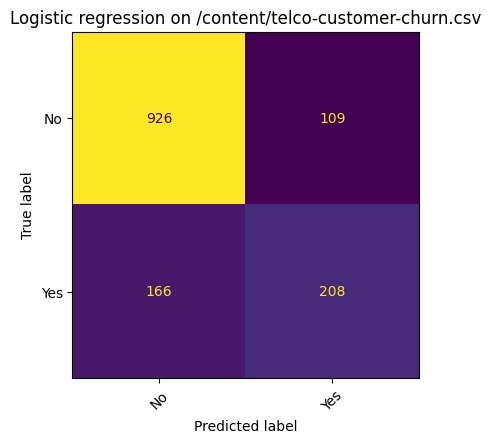

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title("Logistic regression on " + MY_FILE)
plt.show()

---
## Part 2. Tutorial 2 on your data

### 5. Cross-validation on the training rows

From here until section 8, only the training rows are used.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)   # 5 shuffled folds that keep the class shares the same in every fold (Tutorial 2, section 1)
# METRIC = ___   # a scoring name that fits your problem: two classes, e.g. "recall", "f1",
               # "roc_auc"; more than two, "f1_macro" (Tutorial 2, section 3)

METRIC = "roc_auc"


ai4.check("5.1 a two-class target is coded 1 and 0", y_train.nunique() > 2 or set(y_train.unique()) <= {0, 1},
          "recode it in section 2: scikit-learn's recall and F1 need to know which class is 1")
scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=METRIC)["test_score"]
print("baseline, {}: per fold {}, mean {:.3f} +/- {:.3f}".format(METRIC, scores.round(3), scores.mean(), scores.std()))
ai4.check("5.2 the scores are numbers", not np.isnan(scores).any(),
          "nan means this scoring name does not work for your target: if 5.1 failed, fix that first; with more than two classes, use a macro one such as f1_macro")

FAIL  5.1 a two-class target is coded 1 and 0
      hint: recode it in section 2: scikit-learn's recall and F1 need to know which class is 1
baseline, roc_auc: per fold [0.83  0.844 0.836 0.85  0.852], mean 0.842 +/- 0.009
PASS  5.2 the scores are numbers


True

### 6. Experiments

Change one thing at a time, and compare under the same cross-validation.

In [ ]:
experiments = {
    "baseline": pipe,
    # Add at least one variant that changes one thing. Two examples to adapt:
    #   "balanced weights": Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    #   "C=0.1": Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=3000, C=0.1))]),
}

rows = []
for name, candidate in experiments.items():
    s = cross_validate(candidate, X_train, y_train, cv=cv, scoring=METRIC)
    rows.append({"experiment": name, METRIC: s["test_score"].mean(), "spread": s["test_score"].std(),
                 "fit time (s)": s["fit_time"].mean()})
ai4.check("6.1 at least one experiment besides the baseline", len(experiments) >= 2,
          "add a variant to the dictionary above: experimentation is part of what CW1 marks")
pd.DataFrame(rows).round(4)

FAIL  6.1 at least one experiment besides the baseline
      hint: add a variant to the dictionary above: experimentation is part of what CW1 marks


,experiment,roc_auc,spread,fit time (s)
0,baseline,0.8423,0.0085,0.1999


### 6b. Search a dial

Pick an experiment and a dial: a model setting such as `C` or `alpha`, or how many features to
keep (lecture 4b). One search is the minimum. Search more if your results suggest it; a second
dial can go in the same `GRID`. The search tries every value on the same folds; the training
and validation columns side by side show where the model starts to overfit.

In [ ]:
from sklearn.model_selection import GridSearchCV
TUNE = "baseline"   # the experiment to tune, by its name in the table above
GRID = {"model__C": np.logspace(-3, 3, 7)}   # its dial and the values to try, e.g. {"model__C": np.logspace(-3, 3, 7)}
             # (lecture 4b). RandomizedSearchCV works the same way.
search = GridSearchCV(experiments[TUNE], GRID, cv=cv, scoring=METRIC, return_train_score=True)
search.fit(X_train, y_train)
grid_table = pd.DataFrame(search.cv_results_)[["params", "mean_train_score", "mean_test_score", "std_test_score"]]
print("best:", search.best_params_, " cross-validated {}: {:.4f}".format(METRIC, search.best_score_))
experiments[TUNE + ", tuned"] = search.best_estimator_   # so CHOSEN below can pick it
grid_table.round(4)

best: {'model__C': np.float64(1.0)}  cross-validated roc_auc: 0.8423


,params,mean_train_score,mean_test_score,std_test_score
0,{'model__C': 0.001},0.8380,0.8359,0.0097
1,{'model__C': 0.01},0.8453,0.8406,0.0092
2,{'model__C': 0.1},0.8575,0.8417,0.0088
3,{'model__C': 1.0},0.9323,0.8423,0.0085
4,{'model__C': 10.0},0.9990,0.8380,0.0100
5,{'model__C': 100.0},0.9996,0.8332,0.0112
6,{'model__C': 1000.0},0.9996,0.8269,0.0117


In [ ]:
CHOSEN = TUNE + ", tuned"   # the experiment you go with, by its name in the tables: e.g. "baseline", or TUNE + ", tuned"
final = experiments[CHOSEN]

### 7. Score and cost against training size

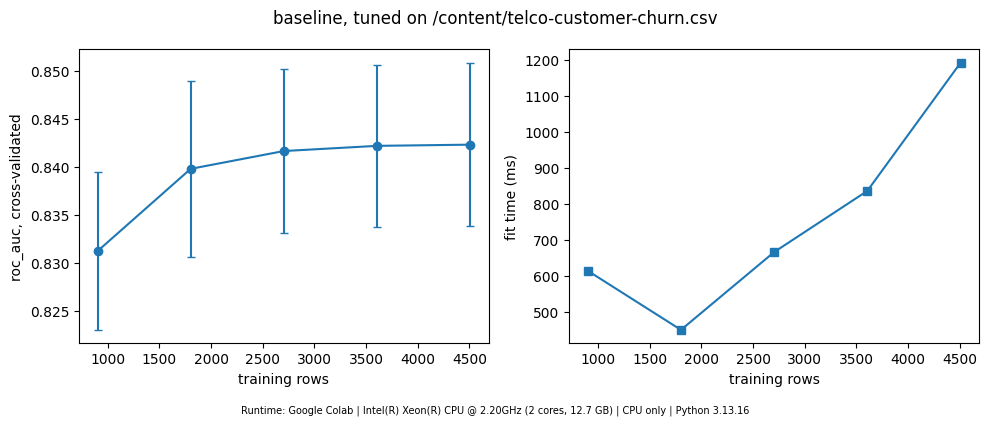

In [ ]:
sizes, _, val_scores, fit_times, _ = learning_curve(final, X_train, y_train, cv=cv, scoring=METRIC,
                                                    train_sizes=np.linspace(0.2, 1.0, 5), return_times=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.errorbar(sizes, val_scores.mean(axis=1), yerr=val_scores.std(axis=1), marker="o", capsize=3)
ax1.set_xlabel("training rows")
ax1.set_ylabel(METRIC + ", cross-validated")
ax2.plot(sizes, fit_times.mean(axis=1) * 1000, "s-")
ax2.set_xlabel("training rows")
ax2.set_ylabel("fit time (ms)")
fig.suptitle(CHOSEN + " on " + MY_FILE)
fig.text(0.5, -0.03, "Runtime: " + RUNTIME, ha="center", fontsize=7)
plt.tight_layout()
plt.show()

### 8. The test set, once

The chosen model, fitted on all the training rows and scored on the test rows: the numbers for your report.

In [ ]:
final.fit(X_train, y_train)
print(classification_report(y_test, final.predict(X_test), zero_division=0))

r = ai4.benchmark(final, X_train, y_train, X_test, y_test, label=CHOSEN)
mb, measured = ai4.peak_memory(lambda: final.fit(X_train, y_train))
ai4.ResultsTable().add(CHOSEN, r, peak_memory_mb=round(mb, 1), memory_measured=measured).df()

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



,model,score,fit_s,predict_ms_per_1k,fit_s_best,predict_s,n_train,n_test,repeats,peak_memory_mb,memory_measured
0,"baseline, tuned",0.804826,1.2828,104.076335,1.142458,0.146644,5634,1409,3,1.8,host process RSS (peak minus baseline)


### 9. The threshold (Stroke and Telco; Steel Plates: delete this section)

Probabilities from cross-validation on the training rows, so the threshold is chosen without the test set.

In [ ]:

# proba = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
# rows = []
# for t in [0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]:
#     p = (proba >= t).astype(int)
#     rows.append({"threshold": t, "precision": precision_score(y_train, p, zero_division=0),
#                  "recall": recall_score(y_train, p), "share flagged": p.mean()})
# pd.DataFrame(rows).round(3)

# 先转换y_train（放在最前面，只运行一次）
y_train_num = y_train.map({"Yes":1, "No":0})

proba = cross_val_predict(final, X_train, y_train_num, cv=cv, method="predict_proba")[:, 1]
rows = []
for t in [0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]:
    p = (proba >= t).astype(int)
    rows.append({
        "threshold": t,
        "precision": precision_score(y_train_num, p, zero_division=0),
        "recall": recall_score(y_train_num, p),
        "share flagged": p.mean()
    })
pd.DataFrame(rows).round(3)

,threshold,precision,recall,share flagged
0,0.9,0.000,0.000,0.000
1,0.8,0.836,0.041,0.013
2,0.7,0.794,0.217,0.072
3,0.6,0.713,0.391,0.146
4,0.5,0.652,0.538,0.219
5,0.4,0.591,0.643,0.289
6,0.3,0.539,0.759,0.374
7,0.2,0.474,0.855,0.479
8,0.1,0.400,0.940,0.624


In [ ]:
# THRESHOLD = 0.3 # from the table: the precision and recall your problem needs (Tutorial 2, section 3)

# p_test = (final.predict_proba(X_test)[:, 1] >= THRESHOLD).astype(int)
# print("test set at threshold {}: precision {:.3f}, recall {:.3f}".format(
#     THRESHOLD, precision_score(y_test, p_test, zero_division=0), recall_score(y_test, p_test)))
# ai4.decision("Threshold " + str(THRESHOLD), "EDIT: what a missed case and a false alarm each cost", cost="no refit")

# 转换测试集标签，只运行一次
y_test_num = y_test.map({"Yes":1, "No":0})

THRESHOLD = 0.3
p_test = (final.predict_proba(X_test)[:, 1] >= THRESHOLD).astype(int)

print("test set at threshold {}: precision {:.3f}, recall {:.3f}".format(
    THRESHOLD,
    precision_score(y_test_num, p_test, zero_division=0),
    recall_score(y_test_num, p_test)
))
ai4.decision("Threshold " + str(THRESHOLD), "EDIT: what a missed case and a false alarm each cost", cost="no refit")


test set at threshold 0.3: precision 0.552, recall 0.770
Decision 1
  Chose:   Threshold 0.3
  Because: EDIT: what a missed case and a false alarm each cost
  Cost:    no refit
  Runtime: Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.16


{'choice': 'Threshold 0.3',
 'why': 'EDIT: what a missed case and a false alarm each cost',
 'cost': 'no refit',
 'runtime': 'Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.16'}

### 10. Decision log

In [ ]:
# Replace each EDIT with one line in your own words: this is your report's method section.
ai4.decision("Dropped " + str(DROP), "EDIT: why each of these columns had to go", cost="none")
ai4.decision("EDIT: what you changed, or nothing", "EDIT: what the overview table showed", cost="none")
ai4.decision(type(cv).__name__ + ", scored on " + METRIC, "EDIT: why this scheme and this metric suit your data", cost="{} fits per comparison".format(cv.get_n_splits()))
ai4.decision("Final model: " + CHOSEN, "EDIT: what the experiments showed, and why this one", cost=r)
ai4.decision_log()

Decision 2
  Chose:   Dropped ['customer_id']
  Because: EDIT: why each of these columns had to go
  Cost:    none
  Runtime: Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.16
Decision 3
  Chose:   EDIT: what you changed, or nothing
  Because: EDIT: what the overview table showed
  Cost:    none
  Runtime: Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.16
Decision 4
  Chose:   StratifiedKFold, scored on roc_auc
  Because: EDIT: why this scheme and this metric suit your data
  Cost:    5 fits per comparison
  Runtime: Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.16
Decision 5
  Chose:   Final model: baseline, tuned
  Because: EDIT: what the experiments showed, and why this one
  Cost:    fit 1.283 s, inference 104.08 ms per 1000 rows
  Runtime: Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.16


,choice,why,cost,runtime
0,Threshold 0.3,EDIT: what a missed case and a false alarm eac...,no refit,Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz ...
1,Dropped ['customer_id'],EDIT: why each of these columns had to go,none,Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz ...
2,"EDIT: what you changed, or nothing",EDIT: what the overview table showed,none,Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz ...
3,"StratifiedKFold, scored on roc_auc",EDIT: why this scheme and this metric suit you...,5 fits per comparison,Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz ...
4,"Final model: baseline, tuned","EDIT: what the experiments showed, and why thi...","fit 1.283 s, inference 104.08 ms per 1000 rows",Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz ...


---
## Before you submit

- Runtime, Restart and run all: every cell runs, top to bottom, with no errors.
- Every number in your report appears in an output above.
- Delete any cell you do not use (Steel Plates: section 9).
- Rename this file `ENG4200_CW1_<your ID>.ipynb` (ENG5338: `ENG5338_CW1_<your ID>.ipynb`) and submit it with your report.